# Multimodal X-ray mapping from the transmitted beam — PHBV + BG 4 %

Reference implementation of the mapping workflow described in

> *Multimodal X-ray mapping from the transmitted beam to guide localized SAXS/WAXS
> on a laboratory instrument.*

The method turns a commercial laboratory SAXS/WAXS instrument (Xenocs Xeuss 2.0) into a
two-dimensional mapping system without any instrumental modification. It exploits the
intrinsic divergence of the beam as a geometric magnifier: at a sample–detector distance
of 6.4 m the ultra-high-resolution (UHR) collimation gives an effective pixel of
36.1 × 42.0 µm, well below the 172 µm physical pixel of the detector. The motorized
sample stage performs two interlaced raster scans offset by half a step, which are
recombined with the *drizzle* algorithm down to a 19.5 µm sampling step.

**Workflow reproduced here**

```
raster scans  ->  construction kernels  ->  transmission and beam-broadening maps
              ->  drizzle (sub-pixel recombination)
              ->  transmission T, absorption mu*t, beam broadening B
              ->  ROI selection on B  ->  localized SAXS / WAXS profiles
```

From a single double scan the same transmitted-beam images yield three complementary maps:

| map | symbol | definition |
|---|---|---|
| transmission | $T(\mathbf{p})$ | $I(\mathbf{p})/I_0$ |
| absorption | $\mu t(\mathbf{p})$ | $-\ln T(\mathbf{p})$ |
| beam broadening | $B(\mathbf{p})$ | $(\sigma/I_c)\,/\,(\sigma_0/I_{c,0})$ |

The first two describe the projected optical thickness; the third provides an independent
contrast modality that reveals heterogeneities invisible in transmission and absorption,
and is used as the operational criterion to place the regions of interest (ROIs) at which
localized SAXS/WAXS is subsequently measured.

**Scope.** This notebook covers the computational procedure only: it goes from the reduced
scan data to the three maps, the ROI selection and the localized SAXS/WAXS profiles, and
stops there. Quantitative peak analysis of the WAXS patterns, the method animations and
the publication-ready figure layouts are deliberately left out; they are not needed to
follow or reproduce the mapping workflow.

**Reproducibility.** The notebook runs entirely on the reduced dataset shipped in `data/`
(~11 MB). See section 4 for what that dataset contains, how it was derived from the ~4.2 GB
of raw detector frames, and which single step cannot be recomputed from it.

## 1. Libraries and configuration

### 1.1 Libraries

Only four third-party packages are needed: `numpy`, `pandas` and `matplotlib` for the
processing and plots, `scikit-image` for the local-maximum search used in the ROI
selection, and `pyFAI` for the azimuthal integration of the 2D SAXS patterns.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import center_of_mass
from skimage.feature import peak_local_max
from mpl_toolkits.axes_grid1 import make_axes_locatable

from pyFAI.integrator.azimuthal import AzimuthalIntegrator
from pyFAI.detectors import Pilatus200k

### 1.2 Experimental parameters and analysis constants

Everything that depends on the experiment is read from `data/metadata.json`, which was
written together with the reduced dataset. The constants defined below are the analysis
parameters of the method; they are grouped here so that no magic number appears further
down in the notebook.

In [2]:
DATA_DIR = Path("data")

with open(DATA_DIR / "metadata.json", encoding="utf-8") as fh:
    META = json.load(fh)

# --------------------------------------------------------------------------
# Geometry of the scan
# --------------------------------------------------------------------------
MOTOR_STEP = META["scan"]["motor_step_mm"]      # mm, one map pixel before drizzle
MAP_STEP = MOTOR_STEP / 2                       # mm/px of the drizzled map (19.5 um)
BLOCKS = META["scan"]["blocks"]                 # points of each interlaced scan

# --------------------------------------------------------------------------
# Analysis windows (in detector pixels)
# --------------------------------------------------------------------------
KERNEL_SIZE = 7          # construction kernel for the transmission map (p_cov = 6.67)
BROADENING_WINDOW = 60   # window on which sigma and I_c are evaluated (Eq. 2)
SCAN_WINDOW = META["scan"]["window_px"]         # stored window, superset of both
BEAM_WINDOW = META["direct_beam"]["window_px"]  # stored direct-beam window

# --------------------------------------------------------------------------
# Sub-pixel recombination (drizzle)
# --------------------------------------------------------------------------
DRIZZLE_SHIFTS = [(0, 0), (0.5, 0.5)]   # scan 2 is offset by half a motor step
DRIZZLE_SCALE = 0.5                     # output grid twice as fine
DRIZZLE_PIXFRAC = 0.6                   # 0 = interlacing, 1 = shift-and-add

# --------------------------------------------------------------------------
# Regions of interest
# --------------------------------------------------------------------------
ROI_X_MM, ROI_Y_MM = 0.24, 0.28   # beam footprint on the sample = ROI extent
ROI_MIN_DISTANCE = 10             # minimum separation between B maxima, in map pixels
N_AUTO_ROIS = 2                   # ROI1 and ROI2 are the two maxima of B
ROI_COLORS = ["#00BFFF", "#009E73", "#CC79A7"]

# --------------------------------------------------------------------------
# Plotting
# --------------------------------------------------------------------------
CMAP = "inferno"
Q_SKIP = 4                        # first SAXS points discarded (beamstop shadow)
WAXS_OFFSET = 20                  # vertical offset between stacked WAXS profiles
BAR_MM = 0.195                    # scale bar length (195 um)

print(f"map step before drizzle : {MOTOR_STEP*1e3:.0f} um")
print(f"map step after drizzle  : {MAP_STEP*1e3:.1f} um")
print(f"scan                    : {len(BLOCKS)} x {BLOCKS[0]} points, "
      f"{META['scan']['exposure_time_s']:.0f} s per point")
print(f"sample-detector distance: {META['scan']['sample_detector_distance_m']} m "
      f"({META['instrument']['collimation']} collimation)")

map step before drizzle : 39 um
map step after drizzle  : 19.5 um
scan                    : 2 x 1024 points, 1 s per point
sample-detector distance: 6.4 m (UHR collimation)


## 2. Functions

All functions used in the notebook are defined here, once, before any use.

### 2.1 Beam metrics and kernel extraction

`image_distribution_analysis` returns the three quantities the beam-broadening metric is
built from: the intensity-weighted centroid, the intensity at that centroid $I_c$, and the
radial second moment $\sigma$ about it. `extract_kernel` is the square crop used both for
the $7\times7$ construction kernel and for the $60\times60$ analysis window.

In [3]:
def image_distribution_analysis(image):
    """Centroid, central intensity and radial spread of a 2D intensity distribution.

    Returns a dict with the centroid pixel, I_c, sigma and the ratio sigma/I_c that
    enters the beam-broadening metric B.
    """
    image = np.asarray(image, dtype=np.float32)
    total = image.sum()
    if total == 0:
        return dict(center=(0, 0), intensity_at_center=0,
                    standard_deviation=0, std_dev_to_intensity_ratio=0)

    y, x = np.indices(image.shape, dtype=np.float32)
    cy = (y * image).sum() / total
    cx = (x * image).sum() / total
    cy_i = int(np.clip(round(cy), 0, image.shape[0] - 1))
    cx_i = int(np.clip(round(cx), 0, image.shape[1] - 1))
    intensity_center = image[cy_i, cx_i]

    var = (((x - cx) ** 2 + (y - cy) ** 2) * image).sum() / total
    std_dev = np.sqrt(var)
    ratio = std_dev / intensity_center if intensity_center != 0 else 0.0
    return {
        'center': (cy_i, cx_i),
        'intensity_at_center': intensity_center,
        'standard_deviation': std_dev,
        'std_dev_to_intensity_ratio': ratio,
    }


def _extract_base(image, cx, cy, size):
    """Square crop of side `size` centred on the pixel (cy, cx)."""
    cx, cy = int(round(cx)), int(round(cy))
    half = size // 2
    y0, x0 = cy - half, cx - half
    return image[max(0, y0):y0 + size, max(0, x0):x0 + size]


def _warn_shape(kernel, size):
    """Warn if the crop was truncated by a detector edge."""
    if kernel.shape != (size, size):
        print(f"WARNING: kernel {kernel.shape}, expected ({size},{size})")
        return False
    return True


def extract_kernel(image, cx, cy, size=7):
    """Construction kernel: raw `size` x `size` crop around the beam position."""
    kernel = _extract_base(image, cx, cy, size)
    _warn_shape(kernel, size)
    return kernel

### 2.2 Map construction and physical alignment

`build_map` implements Eq. (1) of the article. Two regimes share the same function:

* **transmission** (`analysis=False`): the $7\times7$ kernels of neighbouring scan points
  overlap on a common grid of step $\Delta$; the intensity of a map pixel is the average of
  all kernels covering it, $I(\mathbf{p}) = \sum_i K_i(\mathbf{p})/N(\mathbf{p})$. The map
  is then cropped to the region of full coverage, where $N(\mathbf{p}) = 49$ is constant.
* **beam broadening** (`analysis=True`): one scalar per motor position, $\sigma/I_c$
  measured on the $60\times60$ analysis window of Eq. (2) — the same window on which the
  direct-beam reference $B_0$ is evaluated, so that numerator and denominator of $B$ are
  computed identically.

`align_and_crop` re-registers one map onto another using the motor coordinates of their
first pixel, so that maps built with different kernel sizes share the same physical origin
and shape.

In [4]:
def build_map(kernels, positions, kernel_size, analysis=False, crop_uniform=False,
              sigma_ref=0, x0_motor=None, z0_motor=None):
    """Assemble a map from the per-point kernels and the motor positions.

    - `analysis=False`: kernels are deposited on the common grid and averaged by
      coverage (transmission map).
    - `analysis=True` : one scalar per motor position, (sigma - sigma_ref)/I_c measured
      on the whole window passed in (beam-broadening map).

    Returns (map, (x0_motor, z0_motor)) with the motor coordinates of the first pixel.
    """
    x0, z0 = positions[0]
    coords = np.rint((np.array(positions) - [x0, z0]) / MOTOR_STEP).astype(int)
    coords -= coords.min(axis=0)
    center_offset = kernel_size // 2

    if analysis:
        # One scalar per motor position; the first pixel keeps the motor coordinate
        # of the first scan point.
        max_x, max_z = coords.max(axis=0) + 1
        image = np.zeros((max_z, max_x), dtype=np.float32)
        count_map = np.ones((max_z, max_x), dtype=np.int32)
        for kernel, (px, pz) in zip(kernels, coords):
            # sigma and I_c are evaluated on the whole window passed in, i.e. on the
            # 60x60 region of Eq. (2) - the same window used for the B0 reference.
            res = image_distribution_analysis(kernel)
            i_c, sigma = res["intensity_at_center"], res["standard_deviation"]
            if 0 <= pz < image.shape[0] and 0 <= px < image.shape[1] and i_c != 0:
                image[pz, px] = (sigma - sigma_ref) / i_c
    else:
        max_x, max_z = coords.max(axis=0) + kernel_size
        image = np.zeros((max_z, max_x), dtype=np.float32)
        count_map = np.zeros((max_z, max_x), dtype=np.int32)
        for kernel, (px, pz) in zip(kernels, coords):
            x_start, z_start = px - center_offset, pz - center_offset
            x_end, z_end = x_start + kernel_size, z_start + kernel_size
            kx0 = kz0 = 0
            if x_start < 0:
                kx0, x_start = -x_start, 0
            if z_start < 0:
                kz0, z_start = -z_start, 0
            x_end = min(x_end, image.shape[1])
            z_end = min(z_end, image.shape[0])
            if x_end <= x_start or z_end <= z_start:
                continue
            block = kernel[kz0:kz0 + (z_end - z_start), kx0:kx0 + (x_end - x_start)]
            image[z_start:z_end, x_start:x_end] += block
            count_map[z_start:z_end, x_start:x_end] += 1

    np.divide(image, count_map, out=image, where=count_map > 0)

    if crop_uniform:
        max_count = count_map.max()
        if max_count > 0:
            full = np.argwhere(count_map == max_count)
            (ymin, xmin), (ymax, xmax) = full.min(0), full.max(0) + 1
            image = image[ymin:ymax, xmin:xmax]
            print(f"  full-coverage region: {image.shape}, N = {max_count}")
            if x0_motor is not None and (xmin or ymin):
                x0_motor += xmin * MOTOR_STEP
                z0_motor += ymin * MOTOR_STEP
                print(f"  new motor origin: ({x0_motor:.4f} mm, {z0_motor:.4f} mm)")
        else:
            print("  no valid data to crop")

    return image, (x0_motor if x0_motor is not None else x0,
                   z0_motor if z0_motor is not None else z0)


def build_scan_maps(windows, positions, exposure, blocks, kernel_size,
                    analysis=False, crop_uniform=False):
    """Build one map per interlaced scan.

    `windows` holds one detector window per scan point (see section 4). The kernel of
    each point is cropped from the centre of its window and normalized by the exposure
    time, exactly as it would be cropped from the full detector frame.
    """
    maps, origins = [], []
    start = 0
    for n_points in blocks:
        stop = start + n_points
        centre = windows.shape[1] // 2
        kernels = [extract_kernel(w, centre, centre, size=kernel_size) / t
                   for w, t in zip(windows[start:stop], exposure[start:stop])]
        block_positions = [tuple(p) for p in positions[start:stop]]
        print(f"scan {len(maps) + 1}: {len(kernels)} kernels of "
              f"{kernel_size}x{kernel_size} px")
        image, origin = build_map(kernels, block_positions, kernel_size,
                                  analysis=analysis, crop_uniform=crop_uniform,
                                  x0_motor=block_positions[0][0],
                                  z0_motor=block_positions[0][1])
        maps.append(image)
        origins.append(origin)
        start = stop
    return maps, origins


def align_and_crop(coords_ref, shapes_ref, coords_target, imgs_target, step=MOTOR_STEP):
    """Crop each target map so that its first pixel matches the motor coordinate of the
    reference map and it has the same shape."""
    aligned = []
    for c_ref, s_ref, c_tar, img in zip(coords_ref, shapes_ref,
                                        coords_target, imgs_target):
        off_x = int(round((c_ref[0] - c_tar[0]) / step))
        off_z = int(round((c_ref[1] - c_tar[1]) / step))
        rows, cols = s_ref
        aligned.append(img[off_z:off_z + rows, off_x:off_x + cols])
    return aligned

### 2.3 Sub-pixel reconstruction (drizzle)

Implementation of the drizzle algorithm (Fruchter & Hook, 2002) for the two interlaced
scans. Each input pixel is shrunk to a fraction `pixfrac` of its size and dropped on an
output grid of half the original step; its intensity is shared among the output pixels in
proportion to the overlap area, and the accumulated contributions are normalized by the
resulting weight map. Because the overlap is separable in $x$ and $z$, the deposition is
written as two matrix products.

The map is returned already cropped to the region of uniform weight — the only region with
complete coverage from both scans — together with the motor coordinate of its first pixel
corrected for that crop.

In [5]:
def _overlap_matrix(n_in, n_out, shift, scale, drop):
    """1D overlap between input and output pixels (the problem is separable)."""
    centers = (np.arange(n_in) + shift) / scale
    lo = centers - drop / 2
    hi = centers + drop / 2
    out = np.arange(n_out)
    return np.clip(np.minimum(hi[:, None], out + 1)
                   - np.maximum(lo[:, None], out), 0, None)


def drizzle(imgs, shifts, out_size, scale=0.5, pixfrac=1.0, crop_uniform=True,
            x0_motor=0.0, z0_motor=0.0, step=MAP_STEP, rtol=1e-6):
    """Combine dithered maps on a finer grid (vectorized drizzle).

    Returns (map, weight, (x0_motor, z0_motor)). With `crop_uniform=True` the map and
    its weight map are cropped to the region of maximum weight, and the motor
    coordinates of the first pixel are corrected for that crop.
    """
    H, W = out_size
    out = np.zeros((H, W))
    weight = np.zeros((H, W))
    drop = pixfrac / scale
    for img, (dx, dy) in zip(imgs, shifts):
        ny, nx = img.shape
        mask = ~np.isnan(img)
        img0 = np.where(mask, img, 0.0)
        Wx = _overlap_matrix(nx, W, dx, scale, drop)
        Wy = _overlap_matrix(ny, H, dy, scale, drop)
        out += Wy.T @ img0 @ Wx
        weight += Wy.T @ mask.astype(float) @ Wx
    final = np.divide(out, weight, out=np.zeros_like(out), where=weight > 0)

    if crop_uniform:
        w_max = weight.max()
        ys, xs = np.where(np.isclose(weight, w_max, rtol=rtol))
        ymin, ymax = ys.min(), ys.max() + 1
        xmin, xmax = xs.min(), xs.max() + 1
        final = final[ymin:ymax, xmin:xmax]
        weight = weight[ymin:ymax, xmin:xmax]
        print(f"  {W}x{H} px -> uniform-weight region "
              f"{final.shape[1]}x{final.shape[0]} px (w = {w_max:.3f})")
        if xmin or ymin:
            x0_motor += xmin * step
            z0_motor += ymin * step
            print(f"  new motor origin: ({x0_motor:.4f} mm, {z0_motor:.4f} mm)")

    return final, weight, (x0_motor, z0_motor)

### 2.4 Coordinates and figure helpers

The correspondence between map pixels and motor coordinates is what makes the maps
actionable: the ROI positions read off the map are the coordinates sent to the sample
stage.

In [6]:
def pixel_to_motor(x_px, z_px, x0_motor, z0_motor, step=MAP_STEP):
    """Map pixel -> motor coordinates (mm)."""
    return x0_motor + x_px * step, z0_motor + z_px * step


def motor_to_pixel(x_mm, z_mm, x0_motor, z0_motor, step=MAP_STEP):
    """Motor coordinates (mm) -> map pixel."""
    return (x_mm - x0_motor) / step, (z_mm - z0_motor) / step


def draw_roi_marker(ax, cx, cz, size_x, size_z, gap_ratio=0.4, color="white", lw=2):
    """Corner-bracket marker delimiting a ROI, in the units of the axes."""
    half_x, half_z = size_x / 2, size_z / 2
    arm_x = half_x * (1 - gap_ratio)
    arm_z = half_z * (1 - gap_ratio)
    for x_c, sx in ((cx - half_x, 1), (cx + half_x, -1)):
        for z_c, sz in ((cz - half_z, 1), (cz + half_z, -1)):
            ax.plot([x_c, x_c + sx * arm_x], [z_c, z_c], color=color, lw=lw, clip_on=True)
            ax.plot([x_c, x_c], [z_c, z_c + sz * arm_z], color=color, lw=lw, clip_on=True)


def show_pair(img_a, img_b, title_a, title_b, cmap=CMAP, figsize=(10, 4.5)):
    """Two maps side by side sharing the same colour scale."""
    vmin = min(img_a.min(), img_b.min())
    vmax = max(img_a.max(), img_b.max())
    fig, axes = plt.subplots(1, 2, figsize=figsize)
    for ax, img, title in zip(axes, (img_a, img_b), (title_a, title_b)):
        im = ax.imshow(img, cmap=cmap, vmin=vmin, vmax=vmax)
        ax.set_title(title)
        ax.set_xlabel("pixel")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    axes[0].set_ylabel("pixel")
    plt.tight_layout()
    plt.show()

### 2.5 Localized SAXS

The 2D SAXS patterns are integrated azimuthally with pyFAI, using the detector geometry
stored in the metadata. Two detector regions are masked: the beamstop shadow and the gap
between detector modules.

In [7]:
def saxs_mask(data):
    """Boolean mask for the azimuthal integration: beamstop shadow and module gap."""
    mask = np.zeros(data.shape, dtype=bool)
    mask[350:, :50] = data[350:, :50] <= 5    # beamstop shadow
    mask[195:213, :] = True                    # gap between detector modules
    return mask


def integrate_saxs(data, geometry, npt=1000):
    """Azimuthally integrate a 2D SAXS pattern. Returns (q, I) with q in nm^-1."""
    data = np.asarray(data, dtype=float)
    pixel_size = geometry["pixel_size_m"]
    ai = AzimuthalIntegrator(
        dist=geometry["sample_detector_distance_m"],
        detector=Pilatus200k(),
        poni1=geometry["beam_centre_col_row"][1] * pixel_size,
        poni2=geometry["beam_centre_col_row"][0] * pixel_size,
        wavelength=geometry["wavelength_m"],
    )
    return ai.integrate1d(data, npt=npt, unit="q_nm^-1", mask=saxs_mask(data))

## 3. Input data

### 3.1 The reduced dataset

The raw experiment is about 4.2 GB: 5593 detector frames of 407 × 487 float32 pixels. That
is impractical to host on GitHub, so this repository ships a reduced dataset (~11 MB) in
`data/`, produced from the raw frames by `tools/make_reduced_dataset.py`.

The reduction is not arbitrary. Of each 407 × 487 detector frame, the mapping pipeline
only ever reads a window centred on the beam: a 7 × 7 kernel for the transmission map and
the 60 × 60 analysis window for the beam-broadening map. The dataset therefore stores that
60 × 60 window — a superset of both — plus the motor coordinates and the exposure time. Cropping a kernel from the stored
window is arithmetically the same operation as cropping it from the full frame, so the
maps built here are **bit-identical** to those built from the raw data (verified against
the full dataset).

| file | contents |
|---|---|
| `scan_windows.npz` | `windows` (2048, 60, 60) detector windows, one per scan point; `positions` (2048, 2) motor coordinates $(x, z)$ in mm; `exposure` (2048,) in s; `blocks` the two interlaced scans |
| `direct_beam.npz` | `windows` (100, 80, 80) direct-beam windows; `exposure`; `centroid_full_frame` (100, 2) per-frame centroids computed on the full frames |
| `saxs_rois.npz` | `frames` (3, 407, 487) 2D SAXS patterns measured at ROI1–ROI3 |
| `waxs_rois.csv` | azimuthally integrated WAXS profiles at ROI1–ROI3 (2θ in degrees) |
| `metadata.json` | instrument, scan, direct-beam, SAXS and WAXS parameters, plus the measured ROI motor coordinates |

**The one step that cannot be recomputed from the reduced data.** The beam centroid used
to place the direct-beam kernel is an intensity-weighted centroid of the *full* detector
frame. Recomputing it on an 80 × 80 crop shifts it by ≈ 0.9 px in $z$, because the
asymmetric background outside the crop contributes to the full-frame centroid. The
precomputed per-frame centroids are therefore stored in the dataset and used here; the
windows were cropped around the corresponding reference pixel so that every kernel
extraction downstream is exact. Section 5.1 makes this explicit.

**Working with the raw data instead.** `tools/make_reduced_dataset.py` documents the exact
provenance of every array (source folder, frame range, reference pixel). Pointing it at the
raw acquisition folders regenerates `data/` from scratch; the raw frames themselves are
kept outside the repository and are available from the authors.

### 3.2 Loading

In [8]:
scan = np.load(DATA_DIR / "scan_windows.npz")
beam = np.load(DATA_DIR / "direct_beam.npz")
saxs = np.load(DATA_DIR / "saxs_rois.npz")
waxs = pd.read_csv(DATA_DIR / "waxs_rois.csv", index_col=0)

scan_windows = scan["windows"]
scan_positions = scan["positions"]
scan_exposure = scan["exposure"]

beam_windows = beam["windows"]
beam_exposure = beam["exposure"]
beam_centroids = beam["centroid_full_frame"]        # (row, col) per frame

saxs_frames = saxs["frames"]
roi_names = [str(n) for n in saxs["roi_names"]]

print(f"scan        : {scan_windows.shape} windows, "
      f"{len(scan_positions)} motor positions")
print(f"             x in [{scan_positions[:,0].min():.3f}, {scan_positions[:,0].max():.3f}] mm, "
      f"z in [{scan_positions[:,1].min():.3f}, {scan_positions[:,1].max():.3f}] mm")
print(f"direct beam : {beam_windows.shape} windows, "
      f"{beam_exposure[0]:.0f} s each")
print(f"SAXS        : {saxs_frames.shape} patterns at {roi_names}")
print(f"WAXS        : {waxs.shape[0]} points, 2theta in "
      f"[{waxs.index.min():.1f}, {waxs.index.max():.1f}] deg, columns {list(waxs.columns)}")

scan        : (2048, 60, 60) windows, 2048 motor positions
             x in [37.500, 38.728] mm, z in [-35.500, -34.271] mm
direct beam : (100, 80, 80) windows, 1 s each
SAXS        : (3, 407, 487) patterns at ['ROI1', 'ROI2', 'ROI3']
WAXS        : 465 points, 2theta in [14.9, 44.6] deg, columns ['ROI1', 'ROI2', 'ROI3']


## 4. Beam characterisation and reference values

The direct beam (no sample) fixes the two references the maps are normalized by: the
incident intensity $I_0$ and the broadening reference $B_0 = \sigma_0/I_{c,0}$. Both are
averaged over the 100 direct-beam acquisitions of 1 s that precede the scan.

### 4.1 Beam position and the construction kernel

The centroid stored in the dataset was computed on the full detector frames. The cell
below also recomputes it on the stored 80 × 80 windows to quantify the difference
discussed in section 3.1: the two values agree in $x$ but differ by about 0.9 px in $z$,
which is why the full-frame value is the one used.

In [9]:
centroid_full = beam_centroids.mean(axis=0)                 # (row, col)
ref_col, ref_row = META["direct_beam"]["reference_pixel_col_row"]
window_center = BEAM_WINDOW // 2

# same centroid, but evaluated on the stored crop (for comparison only)
crop_centroids = np.array([center_of_mass(np.clip(w, 0, None)) for w in beam_windows])
centroid_crop = crop_centroids.mean(axis=0) + [ref_row - window_center,
                                               ref_col - window_center]

print(f"beam centroid, full detector frame : cx = {centroid_full[1]:.4f}, "
      f"cz = {centroid_full[0]:.4f} px")
print(f"beam centroid, 80x80 stored window : cx = {centroid_crop[1]:.4f}, "
      f"cz = {centroid_crop[0]:.4f} px")
print(f"difference                         : dx = {centroid_crop[1]-centroid_full[1]:+.4f}, "
      f"dz = {centroid_crop[0]-centroid_full[0]:+.4f} px")
print(f"\nreference pixel used for every crop: (col, row) = ({ref_col}, {ref_row})")
print(f"kernel position inside the stored window: ({window_center}, {window_center})")

beam centroid, full detector frame : cx = 241.6135, cz = 308.6399 px
beam centroid, 80x80 stored window : cx = 241.6263, cz = 307.7485 px
difference                         : dx = +0.0128, dz = -0.8914 px

reference pixel used for every crop: (col, row) = (241, 308)
kernel position inside the stored window: (40, 40)


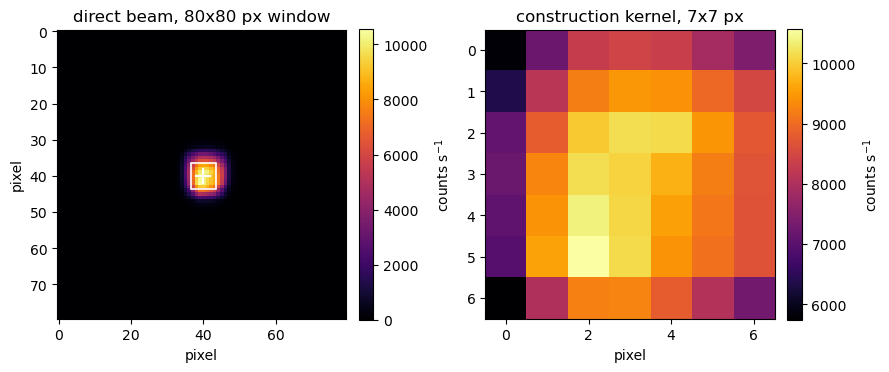

In [10]:
# Direct beam and the 7x7 construction kernel extracted from it (Fig. 1 of the article)
beam_mean = beam_windows.mean(axis=0) / beam_exposure.mean()
kernel_mean = extract_kernel(beam_mean, window_center, window_center, size=KERNEL_SIZE)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
vmax = beam_mean.max()

im = axes[0].imshow(beam_mean, cmap=CMAP, vmax=vmax)
axes[0].plot(window_center, window_center, "+", color="white", ms=12, mew=1.5)
half = KERNEL_SIZE // 2
axes[0].add_patch(plt.Rectangle((window_center - half - 0.5, window_center - half - 0.5),
                                KERNEL_SIZE, KERNEL_SIZE, fill=False,
                                edgecolor="white", lw=1.2))
axes[0].set_title(f"direct beam, {BEAM_WINDOW}x{BEAM_WINDOW} px window")
axes[0].set_xlabel("pixel"); axes[0].set_ylabel("pixel")
fig.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04, label="counts s$^{-1}$")

im = axes[1].imshow(kernel_mean, cmap=CMAP, vmax=vmax)
axes[1].set_title(f"construction kernel, {KERNEL_SIZE}x{KERNEL_SIZE} px")
axes[1].set_xlabel("pixel")
fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04, label="counts s$^{-1}$")

plt.tight_layout()
plt.show()

### 4.2 Incident intensity $I_0$ and broadening reference $B_0$

$I_0$ is the maximum of the exposure-normalized construction kernel, averaged over the 100
direct-beam frames. $B_0 = \sigma_0/I_{c,0}$ is evaluated on the same $60\times60$ window
used later for the sample, so that $B = 1$ is the no-sample reference of the scan.

In [11]:
i0_values, b0_values, sigma0_values, ic0_values = [], [], [], []

for window, exposure in zip(beam_windows, beam_exposure):
    kernel = extract_kernel(window, window_center, window_center,
                            size=KERNEL_SIZE) / exposure
    i0_values.append(kernel.max())

    analysis_window = extract_kernel(window, window_center, window_center,
                                     size=BROADENING_WINDOW) / exposure
    res = image_distribution_analysis(analysis_window)
    sigma0_values.append(res["standard_deviation"])
    ic0_values.append(res["intensity_at_center"])
    b0_values.append(res["std_dev_to_intensity_ratio"])

I0 = float(np.mean(i0_values))
B0 = float(np.mean(b0_values))
sigma0 = float(np.mean(sigma0_values))
ic0 = float(np.mean(ic0_values))

print(f"I0      = {I0:.1f} +/- {np.std(i0_values):.1f} counts/s "
      f"(CV {100*np.std(i0_values)/I0:.2f} %)")
print(f"sigma0  = {sigma0:.3f} +/- {np.std(sigma0_values):.3f} px")
print(f"I_c,0   = {ic0:.1f} +/- {np.std(ic0_values):.1f} counts/s")
print(f"B0      = {B0:.4e} +/- {np.std(b0_values):.1e}")

I0      = 10576.8 +/- 98.6 counts/s (CV 0.93 %)
sigma0  = 4.550 +/- 0.003 px
I_c,0   = 9713.0 +/- 66.5 counts/s
B0      = 4.6842e-04 +/- 3.3e-06


## 5. Map construction from the raster scans

Each of the two interlaced scans is processed independently into two maps: the transmitted
intensity $I_f$ and the beam broadening. Both are built from the same detector windows —
only the size of the region read from each window differs.

### 5.1 Transmitted intensity $I_f$

The $7\times7$ kernels of neighbouring points overlap on the common grid of step
$\Delta = 39$ µm and are averaged by coverage. The map is cropped to the region where
$N(\mathbf{p}) = 49$, i.e. where every pixel receives the full set of contributions.

scan 1: 1024 kernels of 7x7 px
  full-coverage region: (26, 26), N = 49
  new motor origin: (37.6170 mm, -35.3830 mm)
scan 2: 1024 kernels of 7x7 px
  full-coverage region: (26, 26), N = 49
  new motor origin: (37.6365 mm, -35.3635 mm)


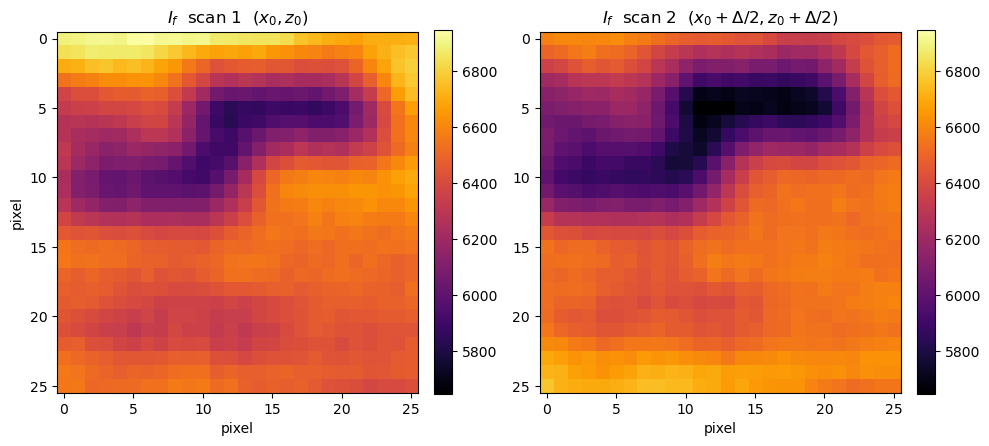

In [12]:
maps_If, origins_If = build_scan_maps(
    scan_windows, scan_positions, scan_exposure, BLOCKS,
    kernel_size=KERNEL_SIZE, analysis=False, crop_uniform=True)

show_pair(maps_If[0], maps_If[1],
          r"$I_f$  scan 1  ($x_0, z_0$)",
          r"$I_f$  scan 2  ($x_0+\Delta/2, z_0+\Delta/2$)")

### 5.2 Beam broadening $B$

One scalar per motor position, $\sigma/I_c$, normalized by the direct-beam reference $B_0$
so that $B = 1$ corresponds to the unperturbed beam (Eq. 2 of the article).

scan 1: 1024 kernels of 60x60 px
  full-coverage region: (32, 32), N = 1
scan 2: 1024 kernels of 60x60 px
  full-coverage region: (32, 32), N = 1


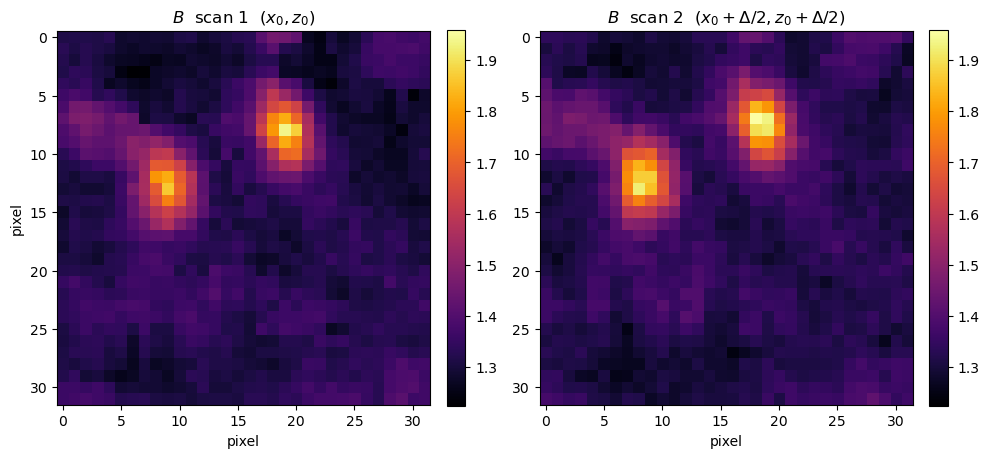

In [13]:
maps_B_raw, origins_B = build_scan_maps(
    scan_windows, scan_positions, scan_exposure, BLOCKS,
    kernel_size=BROADENING_WINDOW, analysis=True, crop_uniform=True)

maps_B = [m / B0 for m in maps_B_raw]

show_pair(maps_B[0], maps_B[1],
          r"$B$  scan 1  ($x_0, z_0$)",
          r"$B$  scan 2  ($x_0+\Delta/2, z_0+\Delta/2$)")

### 5.3 Transmission $T = I_f / I_0$

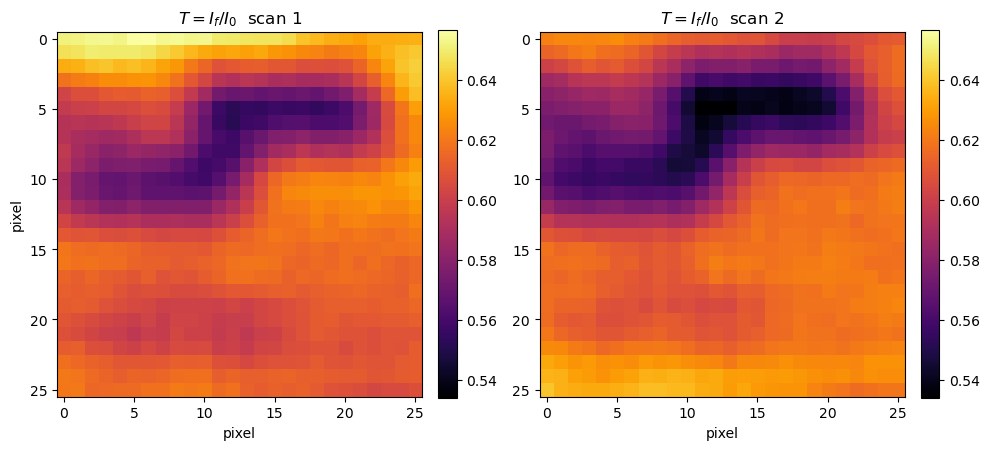

In [14]:
transmission_scans = [m / I0 for m in maps_If]

show_pair(transmission_scans[0], transmission_scans[1],
          r"$T = I_f/I_0$  scan 1", r"$T = I_f/I_0$  scan 2")

## 6. Drizzle reconstruction

The two scans are offset by half a motor step in $x$ and $z$. Drizzle recombines them on a
grid of half the step (`scale=0.5`), shrinking each input pixel to `pixfrac=0.6` of its
size before depositing it, which is what converts the half-step offset into distinct
output positions instead of an average. The sampling step of the reconstructed maps is
19.5 µm.

Transmission and beam broadening are drizzled independently; the absorption map is derived
from the reconstructed transmission map.

In [15]:
transmission, weight_T, origin_T = drizzle(
    transmission_scans, DRIZZLE_SHIFTS,
    out_size=(transmission_scans[0].shape[0] * 2, transmission_scans[0].shape[1] * 2),
    scale=DRIZZLE_SCALE, pixfrac=DRIZZLE_PIXFRAC,
    x0_motor=origins_If[0][0], z0_motor=origins_If[0][1])

broadening_raw, weight_B, origin_B = drizzle(
    maps_B, DRIZZLE_SHIFTS,
    out_size=(maps_B[0].shape[0] * 2, maps_B[0].shape[1] * 2),
    scale=DRIZZLE_SCALE, pixfrac=DRIZZLE_PIXFRAC,
    x0_motor=origins_B[0][0], z0_motor=origins_B[0][1])

  52x52 px -> uniform-weight region 51x51 px (w = 0.720)
  64x64 px -> uniform-weight region 63x63 px (w = 0.720)


### 6.1 Alignment of the two reconstructed maps

The transmission and broadening maps are built with different kernel sizes and therefore
lose different amounts of border when cropped to full coverage. They are brought onto a
common grid using the motor coordinate of their first pixel, so that the two maps and the
ROI coordinates all refer to the same physical origin.

Note on the field of view: `drizzle` returns the map cropped to the region of uniform
weight, which drops the last row and column of the 52 x 52 output grid. The article quotes
the field of the uncropped grid, 1.01 x 1.01 mm; the maps below cover 0.99 x 0.99 mm.

In [16]:
broadening = align_and_crop(
    coords_ref=[origin_T],
    shapes_ref=[transmission.shape],
    coords_target=[origin_B],
    imgs_target=[broadening_raw],
    step=MAP_STEP)[0]

x0_motor, z0_motor = origin_T
field_x = transmission.shape[1] * MAP_STEP
field_z = transmission.shape[0] * MAP_STEP

print(f"reconstructed maps: {transmission.shape} px, "
      f"sampling step {MAP_STEP*1e3:.1f} um")
print(f"field of view     : {field_x:.2f} x {field_z:.2f} mm")
print(f"motor origin      : x = {x0_motor:.4f} mm, z = {z0_motor:.4f} mm")

reconstructed maps: (51, 51) px, sampling step 19.5 um
field of view     : 0.99 x 0.99 mm
motor origin      : x = 37.6170 mm, z = -35.3830 mm


## 7. Transmission, absorption and beam-broadening maps

The absorption map follows from Beer–Lambert, $\mu t = -\ln T$. The three maps below are
the ones reported in the article for the PHBV + BG 4 % film.

transmission T       range [0.543, 0.641]
absorption mu*t      range [0.445, 0.611]
beam broadening B    range [1.238, 1.948]


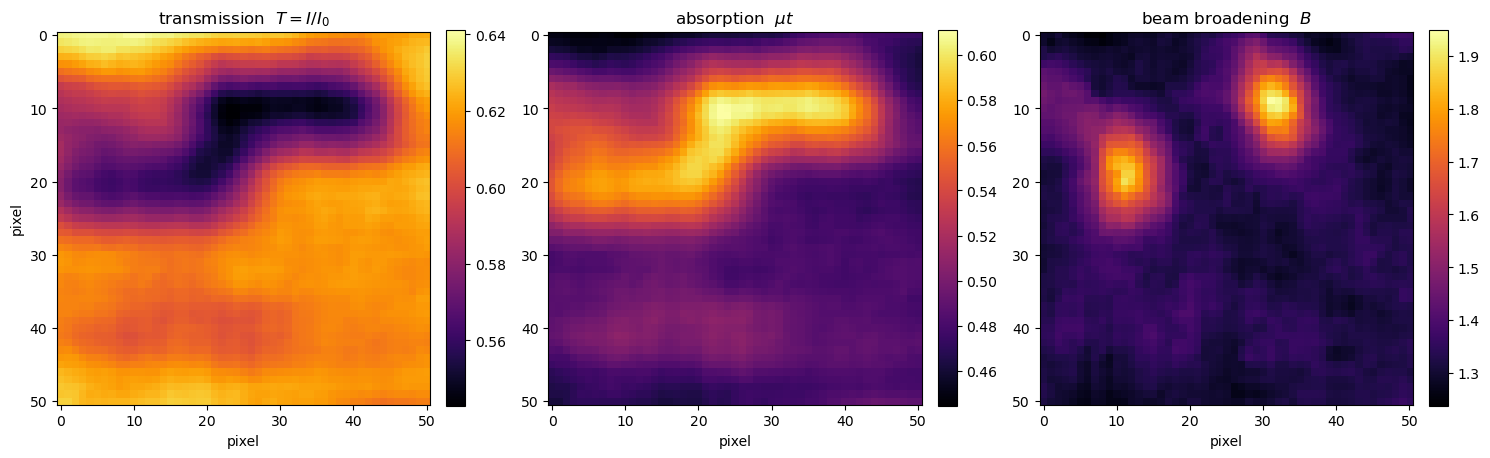

In [17]:
absorption = -np.log(transmission)

maps = [
    (transmission, r"transmission  $T = I/I_0$", "transmission T"),
    (absorption,   r"absorption  $\mu t$",      "absorption mu*t"),
    (broadening,   r"beam broadening  $B$",     "beam broadening B"),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (img, title, label) in zip(axes, maps):
    im = ax.imshow(img, cmap=CMAP)
    ax.set_title(title)
    ax.set_xlabel("pixel")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    print(f"{label:20s} range [{np.nanmin(img):.3f}, {np.nanmax(img):.3f}]")
axes[0].set_ylabel("pixel")
plt.tight_layout()
plt.show()

The transmission and absorption maps describe the same observable, the projected optical
thickness, and are dominated here by a macroscopic variation of the film thickness. The
beam-broadening map shows a qualitatively different distribution: a narrow mode associated
with the matrix plus two isolated maxima that transmission and absorption do not
distinguish from their surroundings. Those two maxima are the heterogeneities the
localized measurements target.

## 8. ROI selection

Following the article, ROI1 and ROI2 are placed automatically on the two maxima of the
beam-broadening map, and ROI3 is set independently on a representative region of the
matrix to act as a reference. The extent of each ROI is the beam footprint on the sample,
0.24 × 0.28 mm.

The motor coordinates recovered from the map are the values that were sent to the sample
stage to perform the localized measurements; the cell below compares them with the
coordinates actually recorded in the SAXS acquisitions, which is a direct check that the
map-to-stage correspondence is correct.

In [18]:
# ROI1 and ROI2: the two maxima of B.
# exclude_border=False keeps peaks close to the border of the (cropped) map.
peaks = peak_local_max(broadening, min_distance=ROI_MIN_DISTANCE,
                       num_peaks=N_AUTO_ROIS, exclude_border=False)

rois = [(x_px, z_px, ROI_COLORS[i - 1], f"ROI{i}")
        for i, (z_px, x_px) in enumerate(peaks, start=1)]

# ROI3: matrix reference, defined by its motor coordinate
roi3 = META["roi_motor_coordinates_mm"]["ROI3"]
x3, z3 = motor_to_pixel(roi3["x"], roi3["z"], x0_motor, z0_motor)
rois.append((round(x3, 2), round(z3, 2), ROI_COLORS[2], "ROI3"))

roi_size_x = ROI_X_MM / MAP_STEP
roi_size_z = ROI_Y_MM / MAP_STEP
print(f"ROI extent: {ROI_X_MM} x {ROI_Y_MM} mm = "
      f"{roi_size_x:.1f} x {roi_size_z:.1f} map pixels\n")

print(f"{'ROI':>5}  {'map pixel':>14}  {'from the map (mm)':>24}  {'measured (mm)':>22}")
for x_px, z_px, _, name in rois:
    x_mm, z_mm = pixel_to_motor(x_px, z_px, x0_motor, z0_motor)
    measured = META["roi_motor_coordinates_mm"][name]
    print(f"{name:>5}  ({x_px:5.1f},{z_px:5.1f})  "
          f"x={x_mm:9.4f}  z={z_mm:9.4f}  "
          f"x={measured['x']:8.3f}  z={measured['z']:8.3f}")

ROI extent: 0.24 x 0.28 mm = 12.3 x 14.4 map pixels

  ROI       map pixel         from the map (mm)           measured (mm)
 ROI1  ( 31.0,  9.0)  x=  38.2215  z= -35.2075  x=  38.221  z= -35.208
 ROI2  ( 11.0, 20.0)  x=  37.8315  z= -34.9930  x=  37.831  z= -34.993
 ROI3  ( 39.0, 39.0)  x=  38.3769  z= -34.6231  x=  38.377  z= -34.623


## 9. Map with the selected ROIs

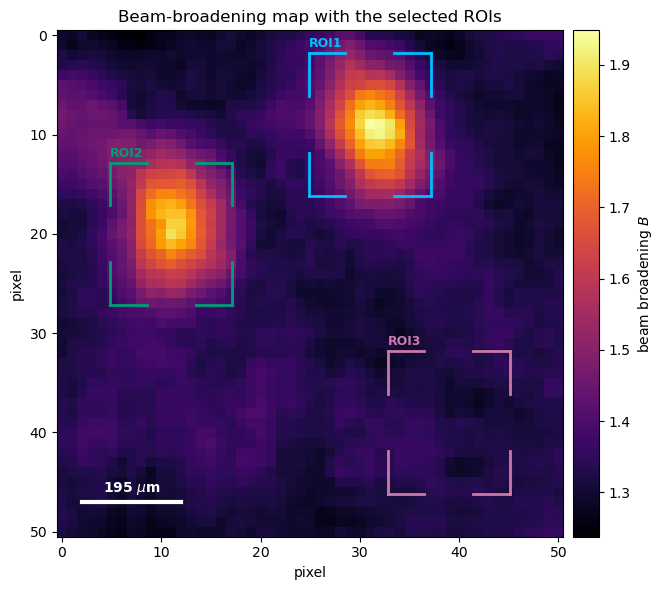

In [19]:
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(broadening, cmap=CMAP)
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.1)
fig.colorbar(im, cax=cax, label=r"beam broadening $B$")

# scale bar: 10 px = 195 um
bar_x, bar_z, bar_len = 2, broadening.shape[0] - 4, 10
ax.plot([bar_x, bar_x + bar_len], [bar_z, bar_z], color="white", lw=3)
ax.text(bar_x + bar_len / 2, bar_z - 0.5, r"195 $\mu$m", color="white",
        ha="center", va="bottom", fontsize=10, fontweight="bold")

for x_px, z_px, color, name in rois:
    draw_roi_marker(ax, x_px, z_px, roi_size_x, roi_size_z, color=color, lw=2)
    ax.text(x_px - roi_size_x / 2, z_px - roi_size_z / 2 - 0.3, name,
            color=color, fontsize=9, fontweight="bold", va="bottom")

ax.set_xlabel("pixel"); ax.set_ylabel("pixel")
ax.set_title("Beam-broadening map with the selected ROIs")
plt.tight_layout()
plt.show()

## 10. Localized SAXS and WAXS profiles

The sample stage was repositioned on each ROI and the scattering patterns were acquired in
the UHR configuration with the SAXS detector at 1.19 m and 2400 s of acquisition, with the
WAXS signal recorded simultaneously by the in-chamber detector.

### 10.1 SAXS

The 2D patterns are integrated azimuthally with pyFAI. The first `Q_SKIP` points are
discarded because they fall in the beamstop shadow.

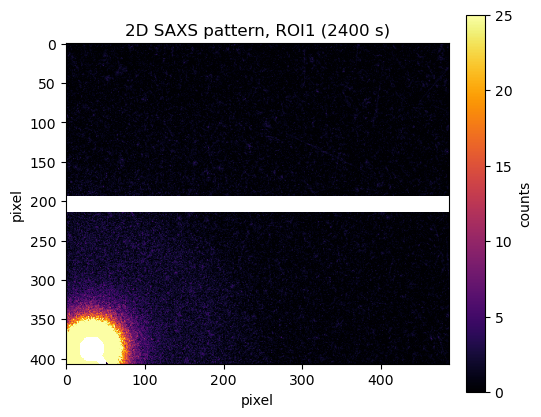

In [20]:
# 2D pattern measured at ROI1, with the masked detector regions shown in white
frame = saxs_frames[0]
masked = np.where(saxs_mask(frame), np.nan, frame)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(masked, cmap=CMAP, vmin=0, vmax=25)
ax.set_title(f"2D SAXS pattern, {roi_names[0]} "
             f"({META['saxs']['exposure_time_s']:.0f} s)")
ax.set_xlabel("pixel"); ax.set_ylabel("pixel")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="counts")
plt.tight_layout()
plt.show()

ROI1: q in [0.097, 3.515] nm^-1, 996 points
ROI2: q in [0.097, 3.515] nm^-1, 996 points
ROI3: q in [0.097, 3.515] nm^-1, 996 points


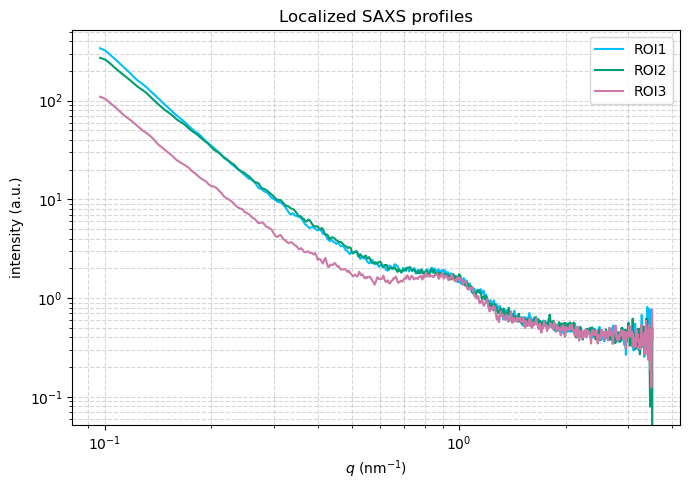

In [21]:
saxs_profiles = [integrate_saxs(f, META["saxs"]) for f in saxs_frames]

fig, ax = plt.subplots(figsize=(7, 5))
for i, (q, intensity) in enumerate(saxs_profiles):
    ax.loglog(q[Q_SKIP:], intensity[Q_SKIP:], lw=1.5,
              label=roi_names[i], color=ROI_COLORS[i])
    print(f"{roi_names[i]}: q in [{q[Q_SKIP]:.3f}, {q.max():.3f}] nm^-1, "
          f"{len(q)-Q_SKIP} points")

ax.set_xlabel(r"$q$ (nm$^{-1}$)")
ax.set_ylabel("intensity (a.u.)")
ax.set_title("Localized SAXS profiles")
ax.grid(True, which="both", ls="--", alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()

ROI1 and ROI2, placed on the maxima of the beam-broadening map, show an excess of
intensity at low $q$ with respect to the matrix (ROI3); the difference vanishes above
$q \approx 0.9$ nm$^{-1}$, where the three curves converge. A difference in optical path
length would scale the profiles over the whole $q$ range, so the fact that the contrast is
confined to low $q$ points to a structural origin rather than to a thickness difference.

### 10.2 WAXS

The WAXS patterns were integrated azimuthally as well; the reduced dataset ships the
integrated profiles. They are shown here to complete the characterisation of the ROIs.
Quantitative peak analysis is outside the scope of this notebook.

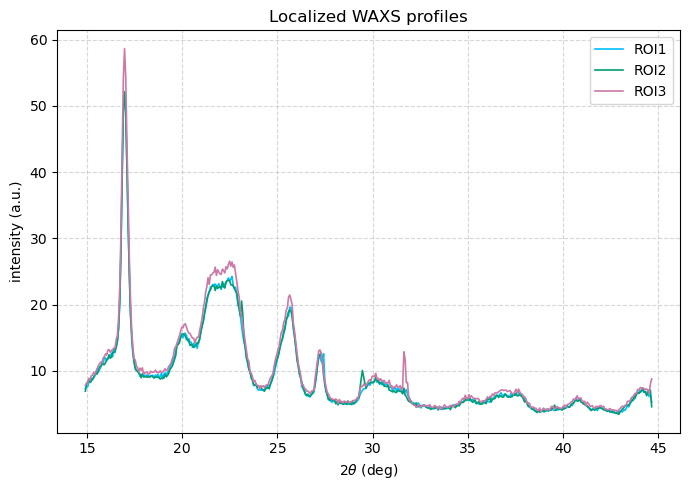

In [22]:
fig, ax = plt.subplots(figsize=(7, 5))
for i, name in enumerate(waxs.columns):
    ax.plot(waxs.index, waxs[name], lw=1.2, label=name, color=ROI_COLORS[i])

ax.set_xlabel(r"$2\theta$ (deg)")
ax.set_ylabel("intensity (a.u.)")
ax.set_title("Localized WAXS profiles")
ax.grid(True, ls="--", alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()

## 11. Combined view: map, SAXS and WAXS

The three panels below summarise the outcome of the workflow: where the ROIs were placed
on the beam-broadening map, and what the localized measurements found there. The map is
shown in physical coordinates (mm), unlike the pixel view of section 9, and the WAXS
profiles are stacked with a fixed offset of 20 counts so that the three are readable.

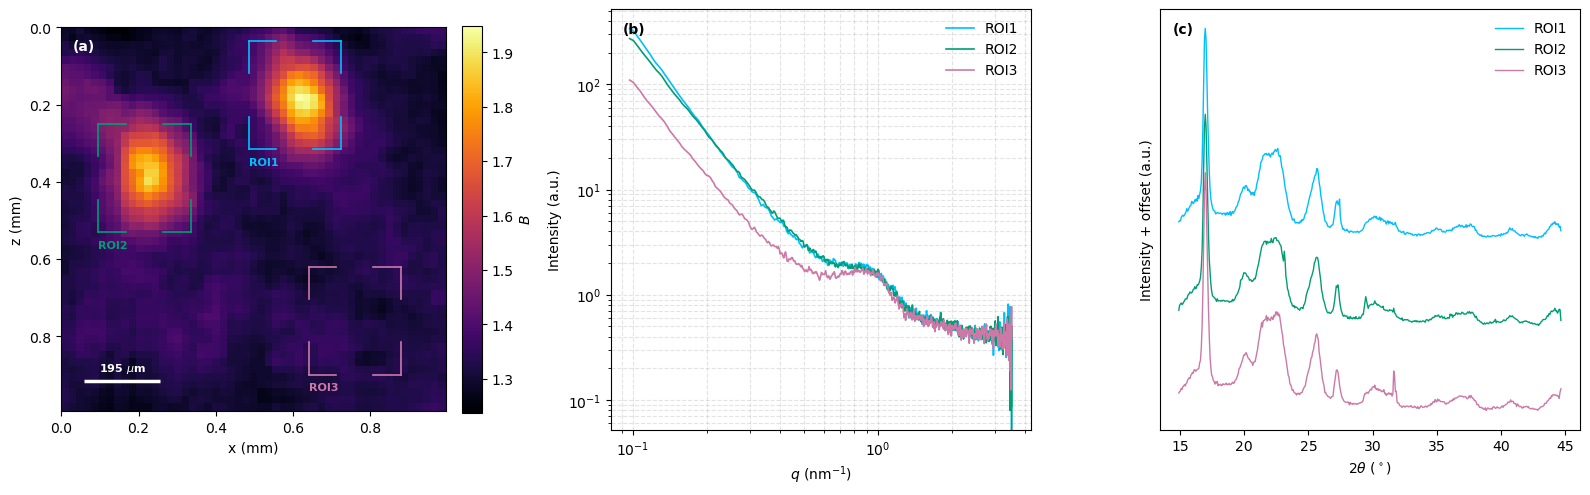

In [23]:
fig, (ax_map, ax_saxs, ax_waxs) = plt.subplots(1, 3, figsize=(16, 5))

# --- (a) beam-broadening map with the selected ROIs, in physical coordinates ---
extent = (0, broadening.shape[1] * MAP_STEP, broadening.shape[0] * MAP_STEP, 0)

im = ax_map.imshow(broadening, cmap=CMAP, extent=extent)
cb = fig.colorbar(im, ax=ax_map, fraction=0.046, pad=0.04)
cb.set_label(r"$B$")

for x_px, z_px, color, name in rois:
    x_mm, z_mm = x_px * MAP_STEP, z_px * MAP_STEP
    draw_roi_marker(ax_map, x_mm, z_mm, ROI_X_MM, ROI_Y_MM, color=color, lw=1.2)
    ax_map.text(x_mm - ROI_X_MM / 2, z_mm + ROI_Y_MM / 2 + 0.02, name,
                color=color, fontsize=8, fontweight="bold", va="top")

# scale bar, lower left
bar_x0 = 0.06 * extent[1]
bar_z = 0.92 * extent[2]
ax_map.plot([bar_x0, bar_x0 + BAR_MM], [bar_z, bar_z], color="white", lw=2.5,
            solid_capstyle="butt")
ax_map.text(bar_x0 + BAR_MM / 2, bar_z - 0.015 * extent[2], r"195 $\mu$m",
            color="white", ha="center", va="bottom", fontsize=8, fontweight="bold")

ax_map.set_xlabel("x (mm)")
ax_map.set_ylabel("z (mm)")
ax_map.set_box_aspect(1)
ax_map.text(0.03, 0.97, "(a)", transform=ax_map.transAxes, color="white",
            fontsize=10, fontweight="bold", va="top")

# --- (b) localized SAXS profiles ---
for i, (q, intensity) in enumerate(saxs_profiles):
    ax_saxs.loglog(q[Q_SKIP:], intensity[Q_SKIP:], lw=1.2,
                   label=roi_names[i], color=ROI_COLORS[i])
ax_saxs.set_xlabel(r"$q$ (nm$^{-1}$)")
ax_saxs.set_ylabel("Intensity (a.u.)")
ax_saxs.grid(True, which="both", ls="--", alpha=0.35)
ax_saxs.legend(frameon=False)
ax_saxs.set_box_aspect(1)
ax_saxs.text(0.03, 0.97, "(b)", transform=ax_saxs.transAxes,
             fontsize=10, fontweight="bold", va="top")

# --- (c) localized WAXS profiles, stacked with a fixed offset ---
# ROI1 on top, ROI3 at the bottom
order = list(waxs.columns)
n_curves = len(order)
for position, name in enumerate(order):
    color = ROI_COLORS[waxs.columns.get_loc(name)]
    ax_waxs.plot(waxs.index,
                 waxs[name] + (n_curves - 1 - position) * WAXS_OFFSET,
                 lw=1.0, label=name, color=color)
ax_waxs.set_xlabel(r"$2\theta$ ($^\circ$)")
ax_waxs.set_ylabel("Intensity + offset (a.u.)")
ax_waxs.set_yticks([])
ax_waxs.legend(frameon=False)
ax_waxs.set_box_aspect(1)
ax_waxs.text(0.03, 0.97, "(c)", transform=ax_waxs.transAxes,
             fontsize=10, fontweight="bold", va="top")

plt.tight_layout()
plt.show()

## 12. Summary

Starting from the reduced scan data, this notebook has reproduced the complete mapping
workflow of the article:

1. the direct beam fixed the construction kernel and the two references $I_0$ and $B_0$;
2. each of the two interlaced raster scans produced a transmitted-intensity map and a
   beam-broadening map from the same detector windows;
3. drizzle recombined them into maps sampled at 19.5 µm, and the two reconstructions were
   brought onto a common physical grid;
4. the three multimodal maps — transmission, absorption and beam broadening — were
   obtained from a single acquisition scheme;
5. two ROIs were located automatically on the maxima of the beam-broadening map and a
   third was placed on the matrix as a reference, and their map pixels were converted into
   motor coordinates;
6. the SAXS and WAXS profiles measured at those coordinates were extracted and displayed,
   and collected next to the map in a single combined view.

The map pixel-to-motor correspondence closes the mapping–localization–characterisation
sequence: the map is not only a spatial representation of the sample, it is the criterion
that decides where to measure.

In [24]:
print(f"reconstructed maps : {transmission.shape} px at {MAP_STEP*1e3:.1f} um "
      f"({field_x:.2f} x {field_z:.2f} mm)")
print(f"transmission T     : [{transmission.min():.3f}, {transmission.max():.3f}]")
print(f"absorption   mu*t  : [{absorption.min():.3f}, {absorption.max():.3f}]")
print(f"broadening   B     : [{broadening.min():.3f}, {broadening.max():.3f}]")
print(f"ROIs               : {[r[3] for r in rois]}")
print(f"SAXS profiles      : {len(saxs_profiles)}")
print(f"WAXS profiles      : {waxs.shape[1]}")

reconstructed maps : (51, 51) px at 19.5 um (0.99 x 0.99 mm)
transmission T     : [0.543, 0.641]
absorption   mu*t  : [0.445, 0.611]
broadening   B     : [1.238, 1.948]
ROIs               : ['ROI1', 'ROI2', 'ROI3']
SAXS profiles      : 3
WAXS profiles      : 3
